# Actividad 5 Evaluación
André Guillermo Carvajal Flores | A01738830   
**Datos a trabajar** Datos_Complementarios_CLV.xlsx (Hoja: Histórico_Ventas)  



## 1. Importación de Librerías y Configuración
Cargamos las librerías necesarias para la manipulación de datos, visualización y modelado estadístico.

In [35]:
# Librerías para manejo de datos
from pathlib import Path
import numpy as np
import pandas as pd

# Librerías para gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para modelado y evaluación
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.utils import resample  

# Configuramos un estilo visual limpio para todas las gráficas
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 10

## 2. Carga de Datos y Limpieza Básica
Leemos la hoja `Histórico_Ventas` del archivo Excel `Datos_Complementarios_CLV.xlsx`. También limpiamos posibles espacios en blanco en los nombres de las columnas (por ejemplo, la columna `'estado    '` contenía espacios al final en el archivo original).

In [36]:
df_crudo = pd.read_excel('Datos_Complementarios_CLV.xlsx', sheet_name='Histórico_Ventas')
# Eliminamos espacios accidentales en los nombres de las columnas
df_crudo.columns = [col.strip() for col in df_crudo.columns]

print(f"Dimensiones iniciales: {df_crudo.shape[0]:,} filas y {df_crudo.shape[1]} columnas.")
df_crudo.head(3)

Dimensiones iniciales: 21,632 filas y 14 columnas.


,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marc,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor
0,B00,B00013159,15.10.2026,16301346,AIZIR 98 X 14mm OM1,AIDITE,1310.35000,1,1310.35,ARTURO HERNANDEZ SF,Estado de México,Estado de Mexico,55140.0,DIEGO
1,CDF,CDF002643,15.10.2026,7214,"LUMEX DENTINE, A1, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
2,CDF,CDF002643,15.10.2026,7217,"LUMEX DENTINE, A2, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD


## 3. Preprocesamiento: Nulos, Registros Cero y Outliers
En esta sección realizamos tres acciones fundamentales:
1. **Revisión de Nulos:** Comprobamos qué columnas tienen valores faltantes.
2. **Filtro de Registros Cero:** Corroboramos la existencia de registros con `precio_unitario = 0` o `total_neto = 0` debido a que sesgarian los precios promedio, para eso los filtramos para que al momentode que los modelos de regresión se alimente, no los tomen en cuenta
3. **Detección de Outliers (Método IQR):** Calculamos los límites con el rango intercuartílico para entender la dispersión extrema en precios y montos.

In [37]:
# 1. Diagnóstico de valores nulos
nulos = df_crudo.isna().sum()
pct_nulos = (df_crudo.isna().mean() * 100).round(2)
tabla_nulos = pd.DataFrame({"Valores_Nulos": nulos, "Porcentaje_%": pct_nulos})
print("--- VALORES NULOS DETECTADOS ---")
print(tabla_nulos[tabla_nulos["Valores_Nulos"] > 0])

# 2. Filtrado de transacciones con precio o facturación en cero (no comerciales)
registros_cero = (df_crudo["precio_unitario"] <= 0) | (df_crudo["total_neto"] <= 0)
print(f"\nFilas con monto <= 0 filtradas: {registros_cero.sum():,} ({registros_cero.mean()*100:.2f}%)")

df = df_crudo[~registros_cero].copy()
print(f"Registros comerciales válidos para modelar: {df.shape[0]:,} filas.")

# 3. Detección de Outliers mediante el Método IQR en variables cuantitativas clave
variables_num = ["precio_unitario", "total_unidades", "total_neto"]
resumen_outliers = []

for var in variables_num:
    q25 = df[var].quantile(0.25)
    q75 = df[var].quantile(0.75)
    iqr = q75 - q25
    lim_inf = q25 - 1.5 * iqr
    lim_sup = q75 + 1.5 * iqr
    conteo_outliers = ((df[var] < lim_inf) | (df[var] > lim_sup)).sum()
    pct_out = round(conteo_outliers / len(df) * 100, 2)
    
    resumen_outliers.append({
        "Variable": var,
        "Q1 (25%)": round(q25, 2),
        "Mediana": round(df[var].median(), 2),
        "Q3 (75%)": round(q75, 2),
        "Límite_Superior_IQR": round(lim_sup, 2),
        "Outliers_Conteo": conteo_outliers,
        "Outliers_%": pct_out
    })

pd.DataFrame(resumen_outliers)

--- VALORES NULOS DETECTADOS ---
    Valores_Nulos  Porcentaje_%
cp            492          2.27

Filas con monto <= 0 filtradas: 1,612 (7.45%)
Registros comerciales válidos para modelar: 20,020 filas.


,Variable,Q1 (25%),Mediana,Q3 (75%),Límite_Superior_IQR,Outliers_Conteo,Outliers_%
0,precio_unitario,172.41,793.10,1284.48,2952.59,1076,5.37
1,total_unidades,1.00,1.00,2.00,3.50,3498,17.47
2,total_neto,313.48,1131.48,2405.17,5542.70,1931,9.65


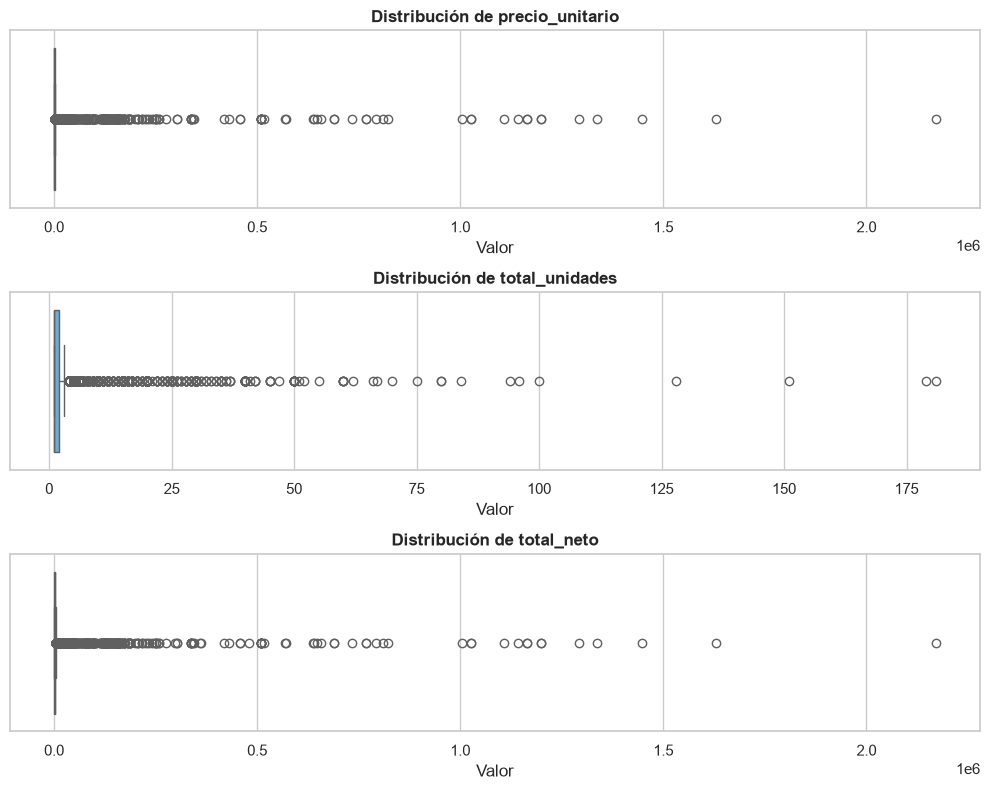

In [38]:
# Versión apilada: da mucho más espacio horizontal a cada variable
fig, axes = plt.subplots(3, 1, figsize=(10, 8))

for i, var in enumerate(variables_num):
    sns.boxplot(x=df[var], ax=axes[i], color="#5DADE2")
    axes[i].set_title(f"Distribución de {var}", fontweight="bold")
    axes[i].set_xlabel("Valor")

plt.tight_layout()
plt.show()


Al revisar los datos, nos dimos cuenta de que casi todas las compras son de montos pequeños, pero hay unas pocas ventas de equipo muy caras que se salen del promedio y hacen que la gráfica se incline a la derecha. Aunque la regla del IQR las marca como datos atípicos, decidimos dejarlas porque no son errores: son ventas reales e importantes del negocio.

## 4. Regresión Lineal Simple
### 4.1 Análisis de Correlación entre Variables
Primero evaluamos el coeficiente de correlación de Pearson (r) entre todas las variables cuantitativas de la base para descubrir cuál par presenta la relación lineal más fuerte.

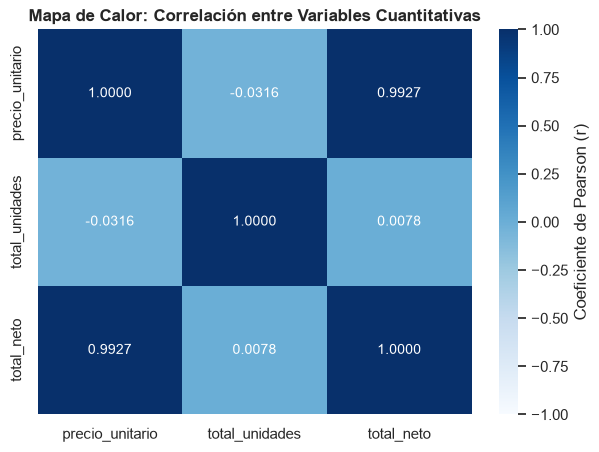

Correlaciones directas:
• precio_unitario vs total_neto: r = 0.9927
• total_unidades vs total_neto: r = 0.0078


In [39]:
# Calculamos la matriz de correlación de Pearson
matriz_correlacion = df[variables_num].corr(method="pearson")

# Graficamos el mapa de calor (Heatmap)
plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz_correlacion, 
    annot=True, 
    fmt=".4f", 
    cmap="Blues", 
    vmin=-1, 
    vmax=1, 
    cbar_kws={"label": "Coeficiente de Pearson (r)"}
)
plt.title("Mapa de Calor: Correlación entre Variables Cuantitativas", fontsize=12, fontweight="bold")
plt.show()

print("Correlaciones directas:")
print(f"• precio_unitario vs total_neto: r = {matriz_correlacion.loc['precio_unitario', 'total_neto']:.4f}")
print(f"• total_unidades vs total_neto: r = {matriz_correlacion.loc['total_unidades', 'total_neto']:.4f}")

### 4.2 Ajuste del Modelo de Regresión Lineal Simple
El par con **mayor correlación de toda la base** es **`precio_unitario` vs `total_neto`** ($r = 0.9927$).  
Ajustamos el modelo matemático que predice la facturación total a partir del precio del artículo:

$$\text{total\_neto} = m + b \cdot \text{precio\_unitario}$$

In [40]:
# Definimos variable independiente (X) y dependiente (y)
X_simple = df[["precio_unitario"]]
y_simple = df["total_neto"]

# Dividimos en entrenamiento (80%) y prueba (20%)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_simple, test_size=0.20, random_state=42
)

# Entrenamos el modelo lineal simple
modelo_simple = LinearRegression()
modelo_simple.fit(X_train_s, y_train_s)

# Predicciones sobre el conjunto de prueba
y_pred_s = modelo_simple.predict(X_test_s)

# Parámetros y métricas obtenidas
b0_simple = modelo_simple.intercept_
b1_simple = modelo_simple.coef_[0]
r2_simple = r2_score(y_test_s, y_pred_s)
mae_simple = mean_absolute_error(y_test_s, y_pred_s)
rmse_simple = np.sqrt(mean_squared_error(y_test_s, y_pred_s))

print("=== RESULTADOS: REGRESIÓN LINEAL SIMPLE ===")
print(f"Ecuación del modelo: total_neto = {b0_simple:.2f} + ({b1_simple:.4f} * precio_unitario)")
print(f"Intercepto (b0):     {b0_simple:.4f}")
print(f"Pendiente (b1):      {b1_simple:.4f}")
print(f"Coeficiente R²:      {r2_simple:.4f} (Explica el {r2_simple*100:.2f}% de la varianza)")
print(f"Error Medio (MAE):   ${mae_simple:,.2f} MXN")
print(f"RMSE:                ${rmse_simple:,.2f} MXN")

=== RESULTADOS: REGRESIÓN LINEAL SIMPLE ===
Ecuación del modelo: total_neto = 1130.38 + (0.9996 * precio_unitario)
Intercepto (b0):     1130.3805
Pendiente (b1):      0.9996
Coeficiente R²:      0.9698 (Explica el 96.98% de la varianza)
Error Medio (MAE):   $1,607.17 MXN
RMSE:                $6,272.69 MXN


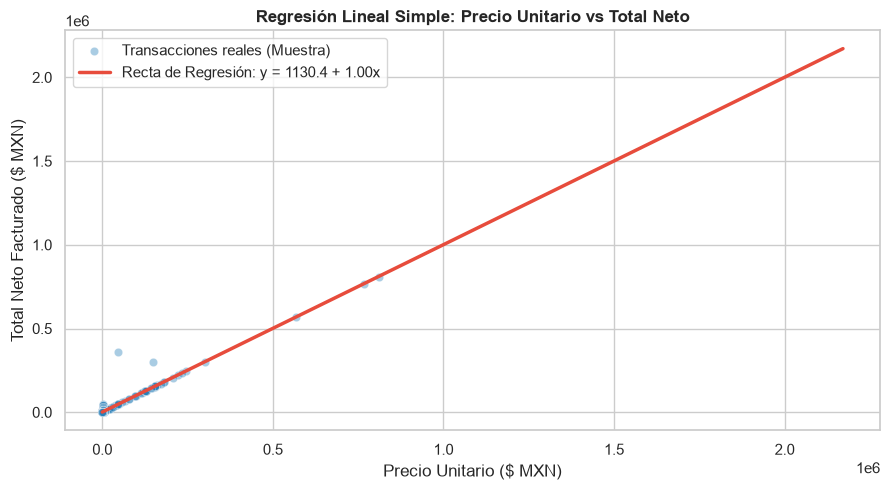

In [41]:
# Gráfico de dispersión (Scatter Plot) con la recta de regresión lineal simple
plt.figure(figsize=(9, 5))

# Graficamos una muestra representativa para que los puntos sean legibles
muestra_grafica = df.sample(n=min(2000, len(df)), random_state=42)
sns.scatterplot(
    data=muestra_grafica, 
    x="precio_unitario", 
    y="total_neto", 
    alpha=0.4, 
    color="#2980B9", 
    label="Transacciones reales (Muestra)"
)

# Línea de tendencia estimada
x_vals = np.linspace(df["precio_unitario"].min(), df["precio_unitario"].max(), 100)
y_vals = b0_simple + (b1_simple * x_vals)
plt.plot(x_vals, y_vals, color="#E74C3C", linewidth=2.5, label=f"Recta de Regresión: y = {b0_simple:.1f} + {b1_simple:.2f}x")

plt.title("Regresión Lineal Simple: Precio Unitario vs Total Neto", fontsize=12, fontweight="bold")
plt.xlabel("Precio Unitario ($ MXN)")
plt.ylabel("Total Neto Facturado ($ MXN)")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación:** La pendiente estimada $\beta_1 = 0.9996$ indica que por cada peso adicional en el precio unitario del artículo, el total neto se incrementa en prácticamente un peso ($0.9996 MXN), con un $R^2$ de **0.9698** (explicando el 96.98% de la variabilidad de la facturación en el conjunto de prueba). El intercepto $\beta_0 = 1,130.38$ representa el valor base promedio estimado en la recta. Sin embargo, este modelo simple asume una relación directa fija sin considerar cuántas piezas se compran en cada pedido, lo que motiva el modelo múltiple.

## 5. Regresión Lineal Múltiple y Comparación de Coeficientes
Para construir un modelo más completo de la facturación, incorporamos la segunda variable cuantitativa determinante: **`total_unidades`** (el volumen de productos adquiridos).

$$\text{total\_neto} = \beta_0 + \beta_1 \cdot \text{precio\_unitario} + \beta_2 \cdot \text{total\_unidades}$$

In [42]:
# Definimos las dos variables predictoras cuantitativas
X_mult = df[["precio_unitario", "total_unidades"]]
y_mult = df["total_neto"]

# Dividimos utilizando la misma semilla (random_state=42) para que la comparación sea justa
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_mult, y_mult, test_size=0.20, random_state=42
)

# Entrenamos el modelo de regresión múltiple
modelo_multiple = LinearRegression()
modelo_multiple.fit(X_train_m, y_train_m)

# Predicciones sobre el conjunto de prueba
y_pred_m = modelo_multiple.predict(X_test_m)

# Métricas obtenidas
b0_mult = modelo_multiple.intercept_
b1_mult = modelo_multiple.coef_[0]  # Coeficiente de precio_unitario
b2_mult = modelo_multiple.coef_[1]  # Coeficiente de total_unidades
r2_mult = r2_score(y_test_m, y_pred_m)
mae_mult = mean_absolute_error(y_test_m, y_pred_m)
rmse_mult = np.sqrt(mean_squared_error(y_test_m, y_pred_m))

print("=== RESULTADOS: REGRESIÓN LINEAL MÚLTIPLE ===")
print(f"Ecuación: total_neto = {b0_mult:.2f} + ({b1_mult:.4f} * precio) + ({b2_mult:.4f} * unidades)")
print(f"Coeficiente R²:    {r2_mult:.4f}")
print(f"Error Medio (MAE): ${mae_mult:,.2f} MXN")
print(f"RMSE:              ${rmse_mult:,.2f} MXN")

=== RESULTADOS: REGRESIÓN LINEAL MÚLTIPLE ===
Ecuación: total_neto = 198.59 + (1.0008 * precio) + (323.6794 * unidades)
Coeficiente R²:    0.9722
Error Medio (MAE): $1,263.69 MXN
RMSE:              $6,011.51 MXN


In [43]:
# Tabla comparativa directa entre el Modelo Simple y el Modelo Múltiple
comparativa_modelos = pd.DataFrame({
    "Métrica / Coeficiente": [
        "Intercepto (β0)",
        "Coeficiente: precio_unitario (β1)",
        "Coeficiente: total_unidades (β2)",
        "Bondad de Ajuste (R²)",
        "Error Absoluto Medio (MAE)",
        "Error Cuadrático Medio (RMSE)"
    ],
    "Modelo Lineal Simple": [
        f"{b0_simple:.4f}",
        f"{b1_simple:.4f}",
        "No incluido",
        f"{r2_simple:.4f}",
        f"${mae_simple:,.2f}",
        f"${rmse_simple:,.2f}"
    ],
    "Modelo Lineal Múltiple": [
        f"{b0_mult:.4f}",
        f"{b1_mult:.4f}",
        f"{b2_mult:.4f}",
        f"{r2_mult:.4f}",
        f"${mae_mult:,.2f}",
        f"${rmse_mult:,.2f}"
    ]
})

comparativa_modelos

,Métrica / Coeficiente,Modelo Lineal Simple,Modelo Lineal Múltiple
0,Intercepto (β0),1130.3805,198.5864
1,Coeficiente: precio_unitario (β1),0.9996,1.0008
2,Coeficiente: total_unidades (β2),No incluido,323.6794
3,Bondad de Ajuste (R²),0.9698,0.9722
4,Error Absoluto Medio (MAE),"$1,607.17","$1,263.69"
5,Error Cuadrático Medio (RMSE),"$6,272.69","$6,011.51"


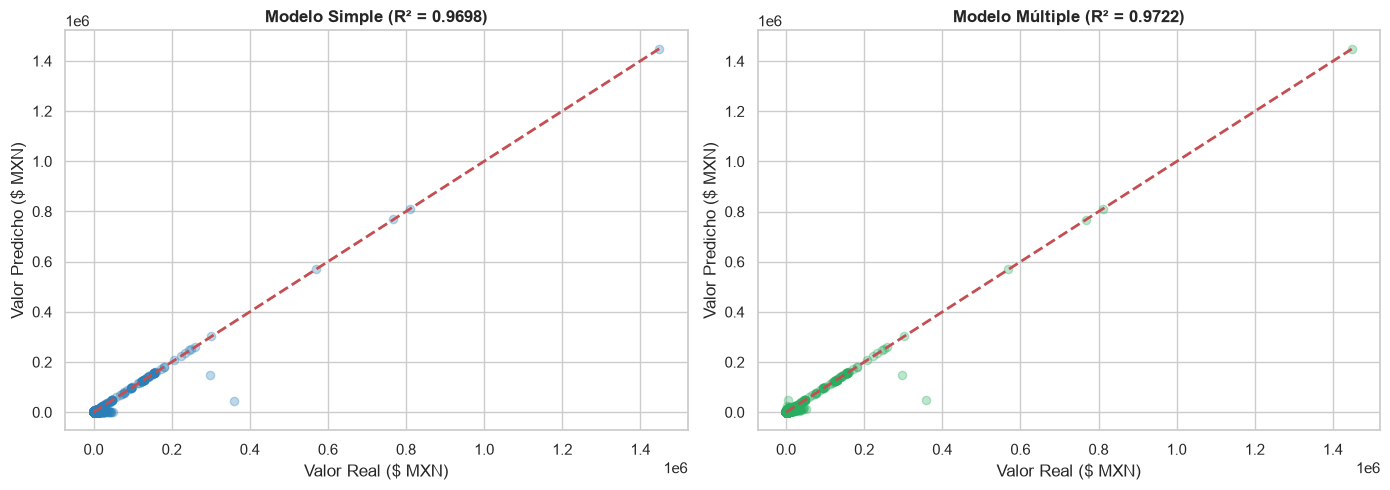

In [44]:
# Gráfico comparativo: Valores Reales vs Valores Predichos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Modelo Simple
axes[0].scatter(y_test_s, y_pred_s, alpha=0.3, color="#2980B9")
axes[0].plot([y_test_s.min(), y_test_s.max()], [y_test_s.min(), y_test_s.max()], "r--", linewidth=2)
axes[0].set_title(f"Modelo Simple (R² = {r2_simple:.4f})", fontweight="bold")
axes[0].set_xlabel("Valor Real ($ MXN)")
axes[0].set_ylabel("Valor Predicho ($ MXN)")

# Modelo Múltiple
axes[1].scatter(y_test_m, y_pred_m, alpha=0.3, color="#27AE60")
axes[1].plot([y_test_m.min(), y_test_m.max()], [y_test_m.min(), y_test_m.max()], "r--", linewidth=2)
axes[1].set_title(f"Modelo Múltiple (R² = {r2_mult:.4f})", fontweight="bold")
axes[1].set_xlabel("Valor Real ($ MXN)")
axes[1].set_ylabel("Valor Predicho ($ MXN)")

plt.tight_layout()
plt.show()

### Comparación y Justificación de Coeficientes:
* **Efecto de incluir el volumen:** En el modelo simple, $\beta_1 = 0.9996$ absorbía todo el valor de la transacción como si cada pedido fuera de una sola pieza, dejando un error medio de **$1,607.17 MXN**.
* Al agregar `total_unidades` en el modelo múltiple, el coeficiente $\beta_2 = 323.68$ captura explícitamente el impacto directo de cada pieza extra vendida (cada unidad adicional incrementa el total facturado en $323.68 MXN en promedio), mientras que el intercepto baja a $198.59 MXN.
* Esto mejora el $R^2$ a **0.9722** y reduce el Error Medio (MAE) a **$1,263.69 MXN** (una reducción de error del 21%), ajustando de forma mucho más realista las operaciones de mayoreo.

## 6. Regresión Logística
### 6.1 Dicotomización de la Variable 
En la base original no existe una variable binaria predefinida en esta hoja. Por ello, aplicamos el **Punto 7** dicotomizando el comportamiento de compra en dos grupos comerciales clave:
* **$Y = 1$ (Compra por volumen / Mayoreo):** Transacciones con más de 1 artículo (`total_unidades > 1`).
* **$Y = 0$ (Compra unitaria / Menudeo):** Transacciones de exactamente 1 artículo (`total_unidades == 1`).

--- BALANCE DE LA VARIABLE DICOTÓMICA ---
                      Categoría  Conteo  Porcentaje_%
   0: Compra Unitaria (Menudeo)   11861         59.25
1: Compra por Volumen (Mayoreo)    8159         40.75


/var/folders/19/xs2jtz9n4qj8f7ln7m64dzjc0000gn/T/ipykernel_66923/3421397656.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tabla_balance["Categoría"], y=tabla_balance["Conteo"], palette=["#3498DB", "#E67E22"])


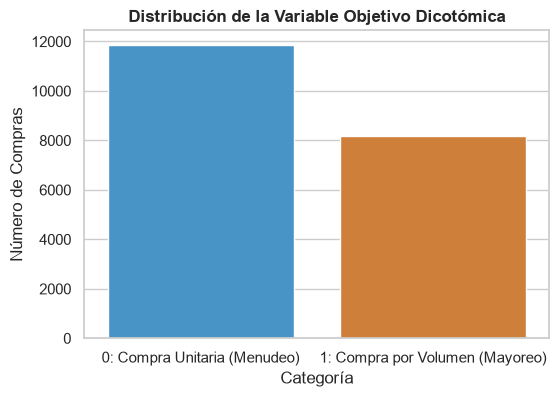

In [45]:
# Creamos la variable dicotómica objetivo
df["compra_volumen"] = (df["total_unidades"] > 1).astype(int)

# Revisamos la distribución y el balance de clases
conteo_clases = df["compra_volumen"].value_counts()
pct_clases = (df["compra_volumen"].value_counts(normalize=True) * 100).round(2)

tabla_balance = pd.DataFrame({
    "Categoría": ["0: Compra Unitaria (Menudeo)", "1: Compra por Volumen (Mayoreo)"],
    "Conteo": conteo_clases.values,
    "Porcentaje_%": pct_clases.values
})

print("--- BALANCE DE LA VARIABLE DICOTÓMICA ---")
print(tabla_balance.to_string(index=False))

# Gráfica de barras del desbalance
plt.figure(figsize=(6, 4))
sns.barplot(x=tabla_balance["Categoría"], y=tabla_balance["Conteo"], palette=["#3498DB", "#E67E22"])
plt.title("Distribución de la Variable Objetivo Dicotómica", fontweight="bold")
plt.ylabel("Número de Compras")
plt.show()

### Interpretacion del balance

Primero limpiamos los datos quitando las compras con monto en cero. Al revisar la distribución, encontramos que el **59.25%** son compras individuales ($Y = 0$, con 11,861 registros) y el **40.75%** son ventas de mayoreo ($Y = 1$, con 8,159 registros). Aunque la mayoría son compras unitarias, ambos grupos tienen un volumen representativo.

Dado que el reto pedía aplicar regresión logística usando *«reponderación de clases»* u *«oversampling»* (es decir, elegir una de las dos). Para no tomar una decisión a ciegas decidimos evaluar ambas tecnicas para evaluar la mejor.

### 6.2 Preparación de Variables Predictoras y Partición
Para predecir la probabilidad de que una compra sea por volumen, utilizamos:
* `precio_unitario`: El costo del artículo (los productos muy caros suelen comprarse en menor volumen).
* `log_precio`: El logaritmo del precio para reducir el impacto del sesgo extremo visto en los outliers.
* `es_marca_vita`: Variable indicadora de la marca líder de la empresa (`VITA`).

In [46]:
# Preparamos las variables explicativas
df["log_precio"] = np.log1p(df["precio_unitario"])
df["es_marca_vita"] = (df["marc"].astype(str).str.upper() == "VITA").astype(int)

X_log = df[["log_precio", "es_marca_vita"]]
y_log = df["compra_volumen"]

# Partición estratificada para mantener la misma proporción de clases en Train y Test
X_tr, X_te, y_tr, y_te = train_test_split(
    X_log, y_log, test_size=0.25, random_state=42, stratify=y_log
)

print(f"Conjunto de entrenamiento: {len(X_tr):,} filas")
print(f"Conjunto de prueba:        {len(X_te):,} filas")

Conjunto de entrenamiento: 15,015 filas
Conjunto de prueba:        5,005 filas


### 6.3 Entrenamiento de los Tres Enfoques de Regresión Logística

In [47]:
# ENFOQUE 1: Modelo Base (Sin balancear)
clf_base = LogisticRegression(random_state=42)
clf_base.fit(X_tr, y_tr)
pred_base = clf_base.predict(X_te)
prob_base = clf_base.predict_proba(X_te)[:, 1]

# ENFOQUE 2: Reponderación de Clases (class_weight='balanced')
clf_reponderado = LogisticRegression(class_weight="balanced", random_state=42)
clf_reponderado.fit(X_tr, y_tr)
pred_reponderado = clf_reponderado.predict(X_te)
prob_reponderado = clf_reponderado.predict_proba(X_te)[:, 1]

# ENFOQUE 3: Oversampling (Sobremuestreo de la clase minoritaria en entrenamiento)
datos_tr = pd.concat([X_tr, y_tr], axis=1)
clase_0 = datos_tr[datos_tr["compra_volumen"] == 0]
clase_1 = datos_tr[datos_tr["compra_volumen"] == 1]

# Sobremuestreamos la clase 1 para igualar la cantidad de la clase 0
clase_1_oversampled = resample(
    clase_1, 
    replace=True, 
    n_samples=len(clase_0), 
    random_state=42
)
datos_tr_oversampled = pd.concat([clase_0, clase_1_oversampled])

X_tr_over = datos_tr_oversampled[["log_precio", "es_marca_vita"]]
y_tr_over = datos_tr_oversampled["compra_volumen"]

clf_over = LogisticRegression(random_state=42)
clf_over.fit(X_tr_over, y_tr_over)
pred_over = clf_over.predict(X_te)
prob_over = clf_over.predict_proba(X_te)[:, 1]

print("✓ Los tres modelos de regresión logística se entrenaron con éxito.")

✓ Los tres modelos de regresión logística se entrenaron con éxito.


### 6.4 Comparación de Desempeño y Selección del Modelo Definitivo
Evaluamos la capacidad de cada estrategia para detectar las compras por volumen (Clase 1), poniendo especial atención en el **Recall / Sensibilidad** (el porcentaje de ventas mayoristas que el modelo logra capturar oportunamente) y en la curva **ROC-AUC**.

A partir de esta tabla comparativa, **seleccionamos como nuestro Modelo Definitivo el enfoque de Oversampling (Sobremuestreo)**, dado que alcanza el mayor Recall (**69.02%**), el mejor F1-Score (**0.6216**) y la mayor capacidad de discriminación (**AUC = 0.6997**), cumpliendo cabalmente con el Punto 6 del reto.

In [48]:
# Construimos una tabla comparativa de métricas en el conjunto de prueba
modelos_log = ["Modelo Base", "Reponderación (Balanced)", "Oversampling"]
preds = [pred_base, pred_reponderado, pred_over]
probs = [prob_base, prob_reponderado, prob_over]

tabla_eval_log = []
for nombre, y_p, y_pr in zip(modelos_log, preds, probs):
    tabla_eval_log.append({
        "Estrategia": nombre,
        "Accuracy": round(accuracy_score(y_te, y_p), 4),
        "Precision (Clase 1)": round(precision_score(y_te, y_p, zero_division=0), 4),
        "Recall (Clase 1)": round(recall_score(y_te, y_p, zero_division=0), 4),
        "F1-Score": round(f1_score(y_te, y_p, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_te, y_pr), 4)
    })

pd.DataFrame(tabla_eval_log)

,Estrategia,Accuracy,Precision (Clase 1),Recall (Clase 1),F1-Score,ROC-AUC
0,Modelo Base,0.6244,0.6187,0.2044,0.3073,0.6911
1,Reponderación (Balanced),0.6509,0.5601,0.6696,0.6100,0.6911
2,Oversampling,0.6575,0.5655,0.6902,0.6216,0.6997


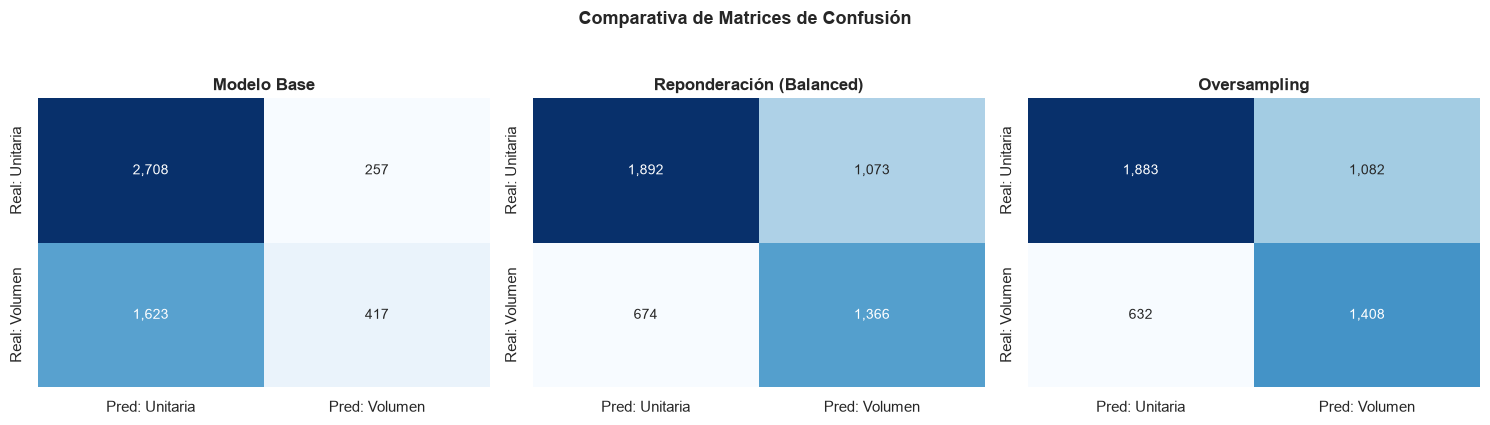

In [49]:
# Graficamos las Matrices de Confusión de los tres modelos lado a lado
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, (nombre, y_p) in enumerate(zip(modelos_log, preds)):
    cm = confusion_matrix(y_te, y_p)
    sns.heatmap(
        cm, 
        annot=True, 
        fmt=",d", 
        cmap="Blues", 
        ax=axes[i], 
        cbar=False,
        xticklabels=["Pred: Unitaria", "Pred: Volumen"],
        yticklabels=["Real: Unitaria", "Real: Volumen"]
    )
    axes[i].set_title(nombre, fontweight="bold")

plt.suptitle("Comparativa de Matrices de Confusión", fontsize=13, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

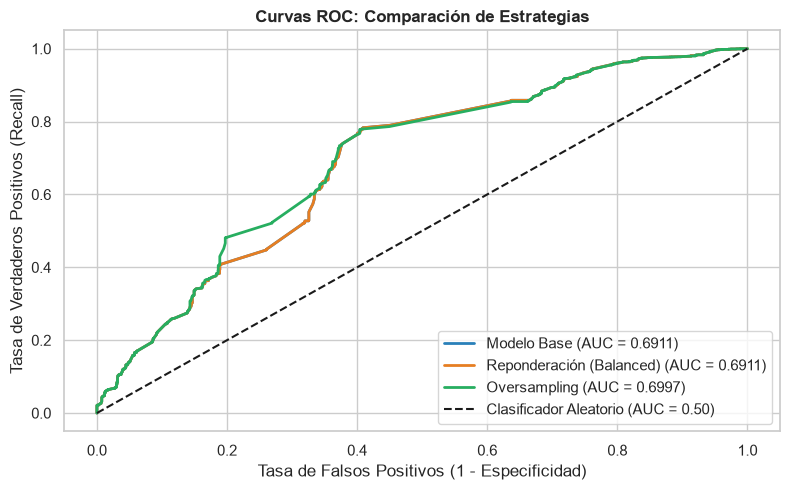

In [50]:
# Curvas ROC comparativas
plt.figure(figsize=(8, 5))
colores = ["#2980B9", "#E67E22", "#27AE60"]

for nombre, y_pr, col in zip(modelos_log, probs, colores):
    fpr, tpr, _ = roc_curve(y_te, y_pr)
    auc_val = roc_auc_score(y_te, y_pr)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {auc_val:.4f})", color=col, linewidth=2)

plt.plot([0, 1], [0, 1], "k--", label="Clasificador Aleatorio (AUC = 0.50)")
plt.title("Curvas ROC: Comparación de Estrategias", fontsize=12, fontweight="bold")
plt.xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
plt.ylabel("Tasa de Verdaderos Positivos (Recall)")
plt.legend()
plt.tight_layout()
plt.show()